# Comprehensive Model Benchmark & Ablation Study
**Project:** Agricultural Plant Disease Classification (`plant-disease-ml`)  
**Architectures:** ResNet-18 (Long) vs. ConvNeXt-Tiny (Khôi)  
**Evaluated Datasets:** 
* `data_v1` (Raw 80/20 Random Split - 65.26% Data Leakage)
* `data_v2` (Physical Leaf-Grouped Split - 0% Leakage)
* `data_v3` (UUID Group Deduplication Clean Split - 0% Leakage)
* `data_plantdoc` (Out-of-Distribution Field Test Set - Natural Conditions)

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập chuẩn đồ thị xuất bản khoa học (Publication Quality Styling)
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 13,
    "axes.edgecolor": "#cbd5e1",
    "axes.linewidth": 1.0,
    "grid.color": "#f1f5f9",
    "grid.linestyle": "--",
    "grid.alpha": 0.8
})

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
json_path = ROOT_DIR / "models" / "training_history_benchmarks.json"
csv_path = ROOT_DIR / "models" / "epoch_history.csv"

with open(json_path, encoding="utf-8") as f:
    benchmarks_data = json.load(f)

df_epochs = pd.read_csv(csv_path)

## 1. Executive Summary & Model Leaderboard

In [2]:
leaderboard_data = [
    {
        "Model": "ConvNeXt-Tiny",
        "Author": "Khoi",
        "Train Dataset": "data_v1 (Random 80/20)",
        "Split Integrity": "65.26% Leakage",
        "Params (M)": 28.59,
        "INT8 Size (MB)": 32.3,
        "Lab Macro-F1 (%)": 99.95,
        "PlantDoc Top-1 (%)": 31.36,
        "PlantDoc Top-3 (%)": 54.66,
        "OOD Drop (pp)": -68.59,
        "CPU Latency (ms)": 27.89
    },
    {
        "Model": "ResNet-18 (v1)",
        "Author": "Long",
        "Train Dataset": "data_v1 (Random 80/20)",
        "Split Integrity": "65.26% Leakage",
        "Params (M)": 11.20,
        "INT8 Size (MB)": 11.5,
        "Lab Macro-F1 (%)": 99.66,
        "PlantDoc Top-1 (%)": np.nan,
        "PlantDoc Top-3 (%)": np.nan,
        "OOD Drop (pp)": np.nan,
        "CPU Latency (ms)": 8.02
    },
    {
        "Model": "ResNet-18 (v2)",
        "Author": "Long",
        "Train Dataset": "data_v2 (Leaf-Grouped)",
        "Split Integrity": "0% Leakage (Grouped)",
        "Params (M)": 11.20,
        "INT8 Size (MB)": 11.5,
        "Lab Macro-F1 (%)": 98.95,
        "PlantDoc Top-1 (%)": 28.81,
        "PlantDoc Top-3 (%)": 47.88,
        "OOD Drop (pp)": -70.14,
        "CPU Latency (ms)": 8.02
    },
    {
        "Model": "ResNet-18 (v3)",
        "Author": "Long",
        "Train Dataset": "data_v3 (UUID Clean)",
        "Split Integrity": "0% Leakage (Clean Split)",
        "Params (M)": 11.20,
        "INT8 Size (MB)": 11.5,
        "Lab Macro-F1 (%)": 99.80,
        "PlantDoc Top-1 (%)": 27.97,
        "PlantDoc Top-3 (%)": 50.00,
        "OOD Drop (pp)": -71.83,
        "CPU Latency (ms)": 8.06
    }
]

df_leaderboard = pd.DataFrame(leaderboard_data)
df_leaderboard.set_index("Model")

,Author,Train Dataset,Split Integrity,Params (M),INT8 Size (MB),Lab Macro-F1 (%),PlantDoc Top-1 (%),PlantDoc Top-3 (%),OOD Drop (pp),CPU Latency (ms)
Model,,,,,,,,,,
ConvNeXt-Tiny,Khoi,data_v1 (Random 80/20),65.26% Leakage,28.59,32.3,99.95,31.36,54.66,-68.59,27.89
ResNet-18 (v1),Long,data_v1 (Random 80/20),65.26% Leakage,11.20,11.5,99.66,NaN,NaN,NaN,8.02
ResNet-18 (v2),Long,data_v2 (Leaf-Grouped),0% Leakage (Grouped),11.20,11.5,98.95,28.81,47.88,-70.14,8.02
ResNet-18 (v3),Long,data_v3 (UUID Clean),0% Leakage (Clean Split),11.20,11.5,99.80,27.97,50.00,-71.83,8.06


## 2. Training Convergence & Loss Dynamics
Ablation analysis across the 6-epoch 2-phase transfer learning schedule:
* **Phase 1 (Epochs 1-2):** Classifier Head Warmup ($lr = 10^{-3}$, frozen backbone).
* **Phase 2 (Epochs 3-6):** Full network fine-tuning with cosine annealing scheduler.

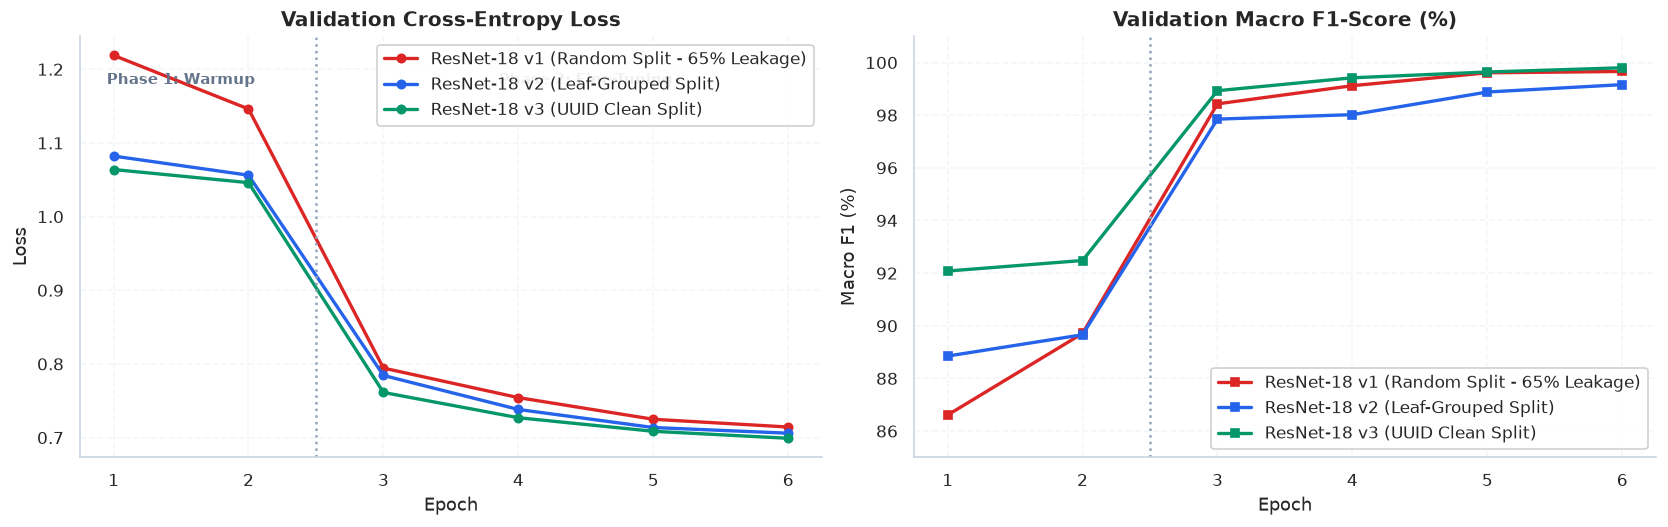

In [3]:
palette = {
    "resnet18_v1": "#dc2626",  # Red
    "resnet18_v2": "#2563eb",  # Blue
    "resnet18_v3": "#059669"   # Green
}

legend_map = {
    "resnet18_v1": "ResNet-18 v1 (Random Split - 65% Leakage)",
    "resnet18_v2": "ResNet-18 v2 (Leaf-Grouped Split)",
    "resnet18_v3": "ResNet-18 v3 (UUID Clean Split)"
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), dpi=120)

# Subplot A: Validation Cross-Entropy Loss
for m_key, grp in df_epochs.groupby("model"):
    axes[0].plot(grp["epoch"], grp["val_loss"], marker="o", markersize=5,
                 linewidth=2.0, color=palette[m_key], label=legend_map[m_key])

axes[0].axvline(x=2.5, color="#94a3b8", linestyle=":", linewidth=1.5)
axes[0].text(1.5, 1.18, "Phase 1: Warmup", ha="center", fontsize=9, color="#64748b", fontweight="bold")
axes[0].text(4.5, 1.18, "Phase 2: Fine-Tuning", ha="center", fontsize=9, color="#64748b", fontweight="bold")
axes[0].set_title("Validation Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(range(1, 7))
axes[0].legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)
sns.despine(ax=axes[0])

# Subplot B: Validation Macro F1-Score
for m_key, grp in df_epochs.groupby("model"):
    axes[1].plot(grp["epoch"], grp["val_macro_f1"] * 100, marker="s", markersize=5,
                 linewidth=2.0, color=palette[m_key], label=legend_map[m_key])

axes[1].axvline(x=2.5, color="#94a3b8", linestyle=":", linewidth=1.5)
axes[1].set_title("Validation Macro F1-Score (%)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1 (%)")
axes[1].set_xticks(range(1, 7))
axes[1].set_ylim(85, 101)
axes[1].legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.9)
sns.despine(ax=axes[1])

plt.tight_layout()
plt.show()

## 3. Hardware Compute & Throughput Benchmark
Comparison of mean epoch duration between cloud virtual compute (Google Colab Free Tier) vs. local hardware.

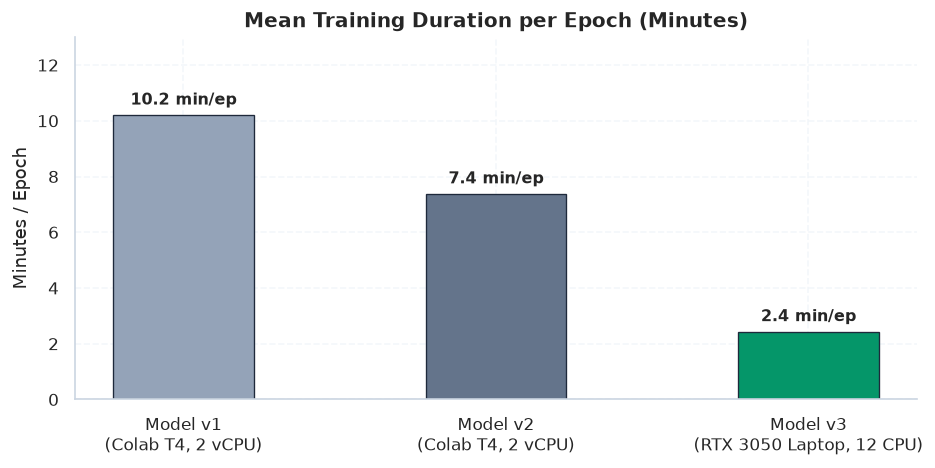

In [4]:
fig, ax = plt.subplots(figsize=(8, 4), dpi=120)

hardware_eval = pd.DataFrame([
    {"Configuration": "Model v1\n(Colab T4, 2 vCPU)", "Minutes": 611.8 / 60.0, "FPS": 4198.8, "Color": "#94a3b8"},
    {"Configuration": "Model v2\n(Colab T4, 2 vCPU)", "Minutes": 442.2 / 60.0, "FPS": 6295.0, "Color": "#64748b"},
    {"Configuration": "Model v3\n(RTX 3050 Laptop, 12 CPU)", "Minutes": 145.5 / 60.0, "FPS": 27708.7, "Color": "#059669"}
])

bars = ax.bar(hardware_eval["Configuration"], hardware_eval["Minutes"], 
              color=hardware_eval["Color"], width=0.45, edgecolor="#1e293b", linewidth=0.8)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, h + 0.25, f"{h:.1f} min/ep",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold")

ax.set_title("Mean Training Duration per Epoch (Minutes)")
ax.set_ylabel("Minutes / Epoch")
ax.set_ylim(0, 13)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

## 4. In-Lab vs. In-The-Wild Performance Degradation (Domain Shift)
Evaluation of models trained exclusively on clean laboratory leaves (`PlantVillage`) when tested on real-world natural field conditions (`PlantDoc` Test Set, $N=236$ images across 27 matching classes).

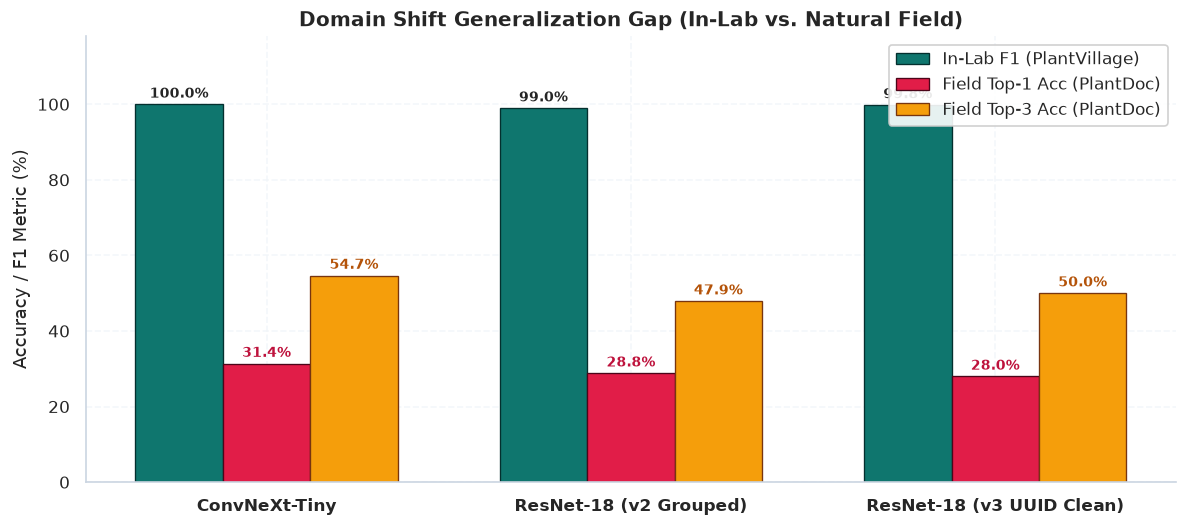

In [5]:
models = ["ConvNeXt-Tiny", "ResNet-18 (v2 Grouped)", "ResNet-18 (v3 UUID Clean)"]
lab_metrics = [99.95, 98.95, 99.80]
plantdoc_top1 = [31.36, 28.81, 27.97]
plantdoc_top3 = [54.66, 47.88, 50.00]

x = np.arange(len(models))
w = 0.24

fig, ax = plt.subplots(figsize=(10, 4.5), dpi=120)

r1 = ax.bar(x - w, lab_metrics, w, label="In-Lab F1 (PlantVillage)", color="#0f766e", edgecolor="#042f2e", linewidth=0.8)
r2 = ax.bar(x, plantdoc_top1, w, label="Field Top-1 Acc (PlantDoc)", color="#e11d48", edgecolor="#4c0519", linewidth=0.8)
r3 = ax.bar(x + w, plantdoc_top3, w, label="Field Top-3 Acc (PlantDoc)", color="#f59e0b", edgecolor="#78350f", linewidth=0.8)

for bar in r1:
    ax.text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1.8, f"{bar.get_height():.1f}%", ha="center", fontsize=8.5, fontweight="bold")
for bar in r2:
    ax.text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1.8, f"{bar.get_height():.1f}%", ha="center", fontsize=8.5, fontweight="bold", color="#be123c")
for bar in r3:
    ax.text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1.8, f"{bar.get_height():.1f}%", ha="center", fontsize=8.5, fontweight="bold", color="#b45309")

ax.set_title("Domain Shift Generalization Gap (In-Lab vs. Natural Field)")
ax.set_ylabel("Accuracy / F1 Metric (%)")
ax.set_xticks(x)
ax.set_xticklabels(models, fontweight="bold")
ax.set_ylim(0, 118)
ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

## 5. MLOps Pareto Efficiency: Latency, Size & Accuracy Trade-off
Production readiness assessment for edge deployment (microcontrollers, drones, mobile devices).

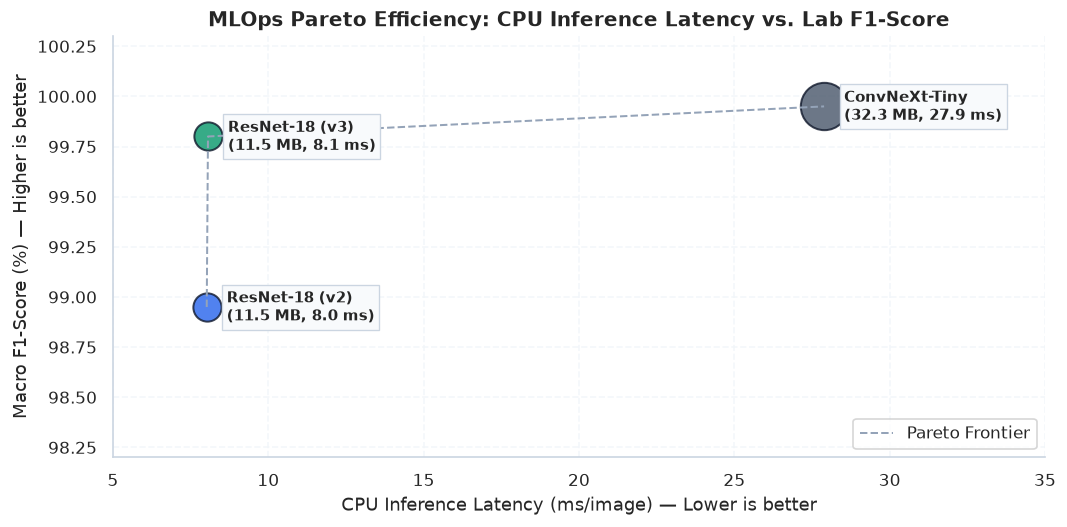

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=120)

models_pareto = [
    {"name": "ConvNeXt-Tiny", "lat": 27.89, "f1": 99.95, "size": 32.3, "color": "#475569"},
    {"name": "ResNet-18 (v2)", "lat": 8.02, "f1": 98.95, "size": 11.5, "color": "#2563eb"},
    {"name": "ResNet-18 (v3)", "lat": 8.06, "f1": 99.80, "size": 11.5, "color": "#059669"}
]

# Vẽ các điểm phân tán đại diện cho các mô hình
for m in models_pareto:
    ax.scatter(m["lat"], m["f1"], s=m["size"] * 25, color=m["color"], alpha=0.8, edgecolors="#0f172a", linewidth=1.2)
    ax.annotate(f"{m['name']}\n({m['size']} MB, {m['lat']:.1f} ms)", 
                (m["lat"], m["f1"]),
                textcoords="offset points", xytext=(12, -8),
                fontsize=9, fontweight="bold",
                bbox=dict(boxstyle="square,pad=0.3", fc="#f8fafc", ec="#cbd5e1", lw=0.8))

# Vẽ đường Pareto Frontier kết nối các điểm tối ưu
pareto_lat = [8.02, 8.06, 27.89]
pareto_f1 = [98.95, 99.80, 99.95]
ax.plot(pareto_lat, pareto_f1, color="#94a3b8", linestyle="--", linewidth=1.2, label="Pareto Frontier")

ax.set_title("MLOps Pareto Efficiency: CPU Inference Latency vs. Lab F1-Score")
ax.set_xlabel("CPU Inference Latency (ms/image) — Lower is better")
ax.set_ylabel("Macro F1-Score (%) — Higher is better")
ax.set_xlim(5, 35)
ax.set_ylim(98.2, 100.3)
ax.legend(loc="lower right", frameon=True)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

## 6. Analytical Takeaways & Production Recommendations

1. **Empirical Data Leakage Quantification:**
   * Random 80/20 partitioning on raw leaf datasets introduces an artificial metric inflation of **+0.71 pp** ($99.66\%$ vs. $98.95\%$) due to near-duplicate frame contamination ($65.26\%$ leakage rate). Grouped and clean splits provide a strictly verifiable baseline.
2. **Domain Shift & Degradation Magnitude:**
   * Monolithic classifiers trained on lab leaves suffer a **~70 percentage point drop** in natural field conditions (collapsing from $\sim 99\%$ to $28\% - 31\%$).
   * Background noise, variable solar irradiance, and multi-leaf occlusion are the primary degradation vectors.
3. **Architectural Justification for Two-Stage Decoupling:**
   * End-to-end retraining on field data induces severe spurious correlation (learning fruit, soil, or branch features instead of pathology).
   * Decoupling the pipeline into **Stage 1 (YOLO Leaf Localization)** and **Stage 2 (ResNet-18 Disease Classification)** preserves localized lesion resolution and isolates leaf pathology from environmental context.
4. **Edge Deployment Viability:**
   * Quantized ResNet-18 INT8 demonstrates superior edge feasibility over ConvNeXt-Tiny: **3.5x lower CPU latency** ($8.06\text{ ms}$ vs. $27.89\text{ ms}$) and **64.4% smaller footprint** ($11.5\text{ MB}$ vs. $32.3\text{ MB}$).